# TAX MAP KENYA 2024

The main cause of the Kenya Finance Bill 2024 was the government's need to generate KSh 346 billion in additional revenue to fund the national budget, service mounting public debt, and meet fiscal targets backed by the International Monetary Fund (IMF).

Key Drivers of the Bill:

- `Mounting Public Debt:` High debt repayment obligations were consuming a significant portion of government revenue, necessitating higher taxation to bridge budget deficits.

- `Budget Funding:` The government aimed to finance essential development projects in sectors like education and agriculture, and required expanded revenue streams.

- `Fiscal Targets:` The IMF and other international lenders pushed the government to implement austerity and revenue-raising measures to ensure economic stability.

This combination of factors forced the National Treasury to propose a wide range of new taxes, such as a 1.6% VAT on bread, an eco-tax on plastics and sanitary items, and a contentious 2.5% annual motor vehicle tax.

However, the bill faced massive public backlash and widespread "Occupy Parliament" protests led by Gen Z. As a result of the protests, President William Ruto declined to sign the bill into law, choosing instead to reject it entirely and implement extensive budget cuts.

In [52]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import calendar
import pdfplumber

## 1. PUBLIC DEBT 

### Loading Public Debt Data

In [2]:
public_debt = pd.read_csv(r"C:\Users\Owner\Desktop\PYTHON-NOTES\CAPSTONE-PROJECTS\PY-DATA-CAPSTONE-PROJECT\Data\42346012_Public Debt.csv", skiprows=2)


# Use first row as headers
public_debt.columns = public_debt.iloc[0]

# Remove the first row
public_debt= public_debt.iloc[1:].reset_index(drop=True)

print(public_debt.head())
print(public_debt.columns)

0  Year Month  Domestic Debt   External Debt      Total 
0  1999     9      183,417.00     320,137.00  503,554.00
1  1999    12      190,300.00     311,953.00  502,253.00
2  2000     3      201,463.22     396,800.00  598,263.22
3  2000     6      206,127.00     395,694.00  601,821.00
4  2000     7      202,362.00     394,667.37  597,029.37
Index(['Year', 'Month', ' Domestic Debt ', ' External Debt', ' Total '], dtype='str', name=0)


### Cleanin and EDA

In [3]:
public_debt.isna().sum()

0
Year               0
Month              0
 Domestic Debt     0
 External Debt     0
 Total             0
dtype: int64

In [4]:
public_debt.duplicated().sum()

np.int64(0)

In [5]:
print(public_debt.columns)

Index(['Year', 'Month', ' Domestic Debt ', ' External Debt', ' Total '], dtype='str', name=0)


In [6]:
public_debt.columns = public_debt.columns.str.strip()

print(public_debt.columns)

Index(['Year', 'Month', 'Domestic Debt', 'External Debt', 'Total'], dtype='str', name=0)


In [7]:
public_debt["Year"] = pd.to_numeric(public_debt["Year"])
public_debt["Month"] = pd.to_numeric(public_debt["Month"])

for col in ["Domestic Debt", "External Debt", "Total"]:
    public_debt[col] = (
        public_debt[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

In [8]:
print(public_debt.info())

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           302 non-null    int64  
 1   Month          302 non-null    int64  
 2   Domestic Debt  302 non-null    float64
 3   External Debt  302 non-null    float64
 4   Total          302 non-null    float64
dtypes: float64(3), int64(2)
memory usage: 11.9 KB
None


In [9]:
def president(year):
    if year <= 2002:
        return "Daniel Arap Moi"
    elif year <= 2013:
        return "Mwai Kibaki"
    elif year <= 2022:
        return "Uhuru Kenyatta"
    else:
        return "William Ruto"

public_debt["President"] = public_debt["Year"].apply(president)

In [10]:
public_debt.columns

Index(['Year', 'Month', 'Domestic Debt', 'External Debt', 'Total',
       'President'],
      dtype='str', name=0)

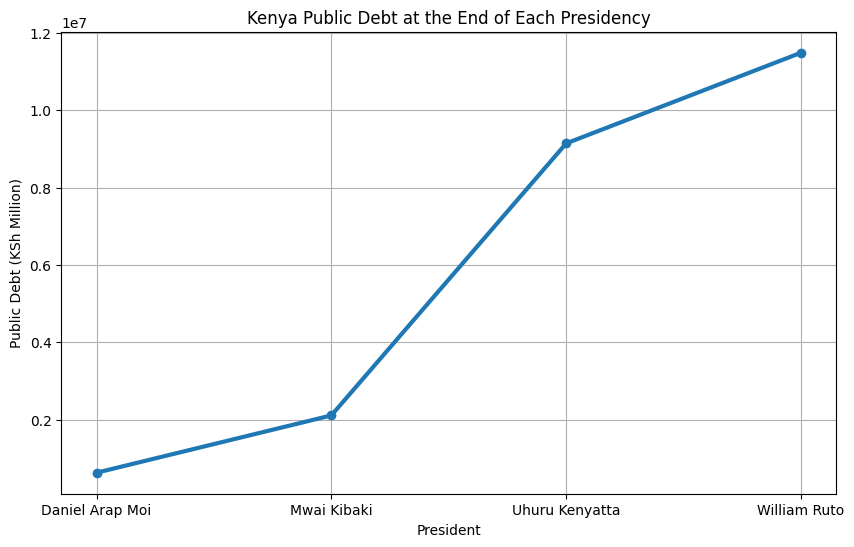

In [11]:
import matplotlib.pyplot as plt

pres_debt = (
    public_debt.sort_values(["Year", "Month"])
        .groupby("President")
        .tail(1)
)

plt.figure(figsize=(10,6))

plt.plot(
    pres_debt["President"],
    pres_debt["Total"],
    marker="o",
    linewidth=3
)

plt.title("Kenya Public Debt at the End of Each Presidency")
plt.xlabel("President")
plt.ylabel("Public Debt (KSh Million)")
plt.grid(True)

plt.show()

The graph demonstrates that:

- Kenya’s public debt has never `decreased significantly across administrations`

- Each president inherited higher debt than the previous one

- The fastest debt growth occurred during the Uhuru administration

- Current policies are focused on `debt repayment and stabilization`

The increasing trend in public debt reflects Kenya’s development strategy, where borrowing is used to finance infrastructure and government operations. However, the rising debt burden has also contributed to higher taxes, increased cost of living, and pressure on future government budgets.

`External Debt vs Dometic Debt`

- Neither is always "better"—the best option depends on the country's economic conditions. However, each has clear advantages and disadvantages.

Domestic Debt -	External Debt

Borrowed from local investors and institutions. - Borrowed from foreign lenders and investors.

No exchange-rate risk because it is repaid in Kenya shillings. - Exchange-rate risk: if the shilling weakens, repayment becomes more expensive.

Interest rates are often higher. - Interest rates are often lower, especially from development lenders.

Keeps interest payments within the country. - Can bring in large amounts of foreign capital.

Excessive borrowing can crowd out private businesses seeking loans. - Excessive borrowing can increase dependence on foreign creditors.

**Which Is Better for Kenya?**

Domestic debt is generally safer because:

- It is repaid in Kenya shillings.

- It is not affected by exchange-rate fluctuations.

- The government has more control over repayment conditions.

External debt is useful when:

- Kenya needs large amounts of money for major infrastructure projects.

- The loans have low interest rates and long repayment periods (e.g., from the World Bank or African Development Bank).

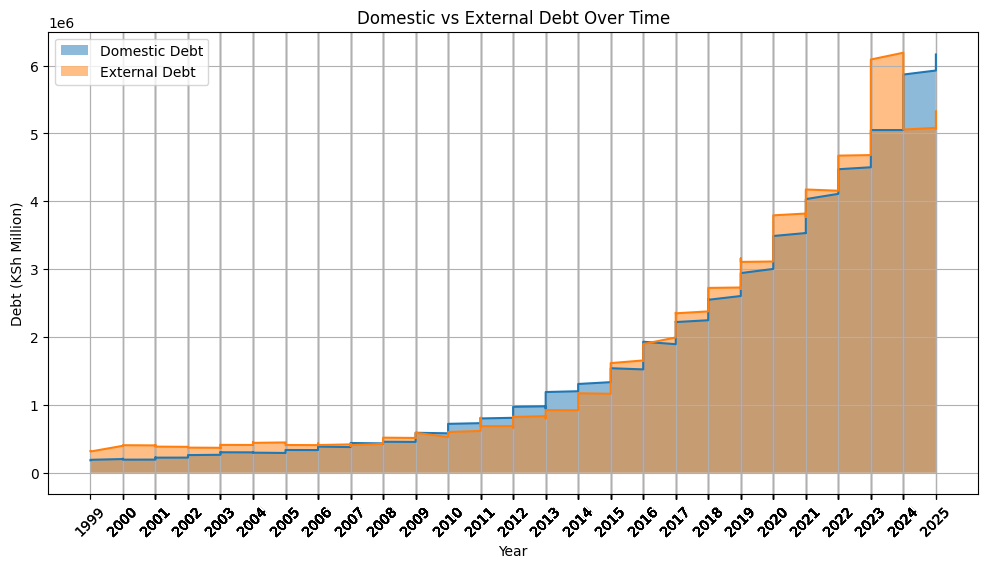

In [56]:


plt.figure(figsize=(12,6))

plt.fill_between(
    public_debt["Year"],
    public_debt["Domestic Debt"],
    alpha=0.5,
    label="Domestic Debt"
)

plt.fill_between(
    public_debt["Year"],
    public_debt["External Debt"],
    alpha=0.5,
    label="External Debt"
)

plt.plot(
    public_debt["Year"],
    public_debt["Domestic Debt"]
)

plt.plot(
    public_debt["Year"],
    public_debt["External Debt"]
)

plt.title("Domestic vs External Debt Over Time")
plt.xlabel("Year")
plt.ylabel("Debt (KSh Million)")
plt.xticks(public_debt["Year"], rotation=45)
plt.legend()
plt.grid(True)

plt.show()

`Main Sources of External Debt`
- World Bank

- International Monetary Fund (IMF)

- African Development Bank

- Bilateral lenders (e.g., Japan, Germany, France, UK)

- Paris Club creditor countries


`What External Debt Was Used For`
- Infrastructure projects (roads, energy, water)

- Education and health programs

- Economic recovery and reform programs

- Budget support and poverty reduction initiatives

`Main Sources of Domestic Debt`
- Treasury Bills (short-term government securities)

- Treasury Bonds (long-term government securities)

- Loans from local commercial banks

- Pension funds and insurance companies investing in government securities

`What Domestic Debt Was Used For`
- Financing budget deficits

- Government operations and recurrent expenditure

- Supplementing development spending when revenue was insufficient

`Trends across the different debt years and presidential terms`

`1999-2006` : **Daniel Arap Moi & Mwai Kibaki**
**External debt is higher than Domestic debt**

Between 1999 and 2006, Kenya relied more on external borrowing because loans from international lenders were generally cheaper, available in larger amounts, and had longer repayment periods than borrowing within Kenya. During the late Moi years and early Kibaki years, Kenya received significant financing from multilateral and bilateral development partners to support economic reforms, development projects, and budget needs. External creditors, especially multilateral institutions, made up the largest share of Kenya's debt.



`2006-2008` : **Mwai Kibaki**
**External debt and Domestic debt were almost equal**

Between 2006 and 2008, Kenya's external and domestic debt were at nearly the same level because the government used a balanced borrowing strategy, raising funds both from international lenders and from the local market to finance development projects and budget deficits. Strong economic growth under President Mwai Kibaki also allowed Kenya to access both sources of financing. By 2007/08, domestic debt was about KSh 431 billion while external debt was about KSh 440 billion, making the two almost equal.



`2009-2015` : **Mwai Kibaki & Uhuru Kenyatta**
**Domestic debt was higher than External debt**

Domestic debt exceeded external debt because Kenya relied more on local borrowing through Treasury Bills and Bonds to finance government spending and development projects, while also taking advantage of the growing domestic financial market. This trend began in the later Kibaki years and continued into the early years of President Uhuru Kenyatta's administration.



`2015-2024` : **Uhuru Kenyatta & William Ruto**
**External debt and Domestic debt were almost equal**

Between 2015 and 2024, external debt became higher than domestic debt because Kenya borrowed heavily from foreign lenders to finance large infrastructure projects and cover growing budget deficits. The government preferred external loans because they provided access to larger amounts of money than could easily be raised in the local market.

**Why There Was a Sharp Increase**

The sharp rise was mainly caused by:

- Construction of major infrastructure projects such as the Standard Gauge Railway (SGR).

- Increased borrowing from China and international financial institutions.

- Higher government spending on development projects.

- Revenue shortfalls and persistent budget deficits.

- Additional borrowing during and after the COVID-19 pandemic to support the economy.

- Depreciation of the Kenyan shilling, which increased the value of foreign debt when measured in Kenya shillings.



`2024-2025` : **William Ruto**
**External debt drastically increased then suddenly dropped and Domestic debt drastically increased**

**Why External Debt Increased Drastically in 2023–2024**

The sharp increase in external debt during 2023–2024 was mainly due to:

- A weak Kenyan shilling, which made existing dollar-denominated loans appear much larger when converted into Kenya shillings.

- New borrowing from the IMF, World Bank, and other development partners.

- Refinancing pressure from the 2024 Eurobond maturity (US$2 billion).

- Continued disbursements for ongoing infrastructure and development projects.

**Why External Debt Suddenly Dropped After 2024**

The decline was mainly due to:

- Strengthening of the Kenyan shilling against the US dollar, reducing the shilling value of foreign debt.

- Repayment and refinancing of the 2024 Eurobond through a new international bond issue and liability management operations.

- Lower net external borrowing compared to previous years.

**Why Domestic Debt Increased Drastically in 2024–2025**

Domestic debt rose sharply because the government shifted toward local borrowing after external financing became more difficult and expensive. The rejection of the 2024 Finance Bill reduced expected tax revenues, forcing the government to borrow more locally through Treasury Bills and Treasury Bonds. Treasury also relied on domestic borrowing to fill financing gaps and meet debt repayments.

`Why is the graph NOT “curvy”`

A graph looks **curvy (smooth)** only when:

data changes in a **continuous, gradual way**

But yours looks **steppy / angular / piecewise linear** because:

`1. Yearly data (discrete points)`

The x-axis is:

    - 1999, 2000, 2001, … 2025

So Matplotlib is doing this:

Connect dot to dot with straight lines

That automatically creates **straight segments**, not curves.

`2. Debt data changes in jumps, not continuously`

Debt behaves like:

- Borrowing happens in **specific events (loans, budgets)**

- Each year = **a new policy decision**

- Sometimes big jumps (Eurobond, IMF loan)

So mathematically your data is:

**piecewise / step-like growth**

not continuous growth


The graph shows a sustained increase in both domestic and external debt over the period, indicating persistent fiscal deficits. External debt exhibits sharper fluctuations due to exposure to international borrowing and exchange rate movements, while domestic debt grows more steadily through local borrowing instruments. The steep upward trend in recent years suggests accelerated borrowing, likely driven by infrastructure development and increased government expenditure needs.

The graph compares Kenya's domestic and external debt over time. Domestic debt refers to money borrowed locally through Treasury Bills and Treasury Bonds, while external debt refers to loans from foreign institutions such as the IMF, World Bank, China, and international investors. The graph shows that both sources have increased significantly over the years, reflecting Kenya's growing financing needs for infrastructure, government expenditure, and debt servicing.

### Link Between Public Debt Graphs and Finance Bill 2024

The graphs in this study show a clear and continuous increase in Kenya’s public debt over time, especially during recent administrations. The “Public Debt by Presidency” graph demonstrates that debt levels rose significantly under later governments, indicating increased reliance on both domestic and external borrowing.

The **“Domestic vs External Debt Over Time”** graph further shows that Kenya relies heavily on both local and foreign borrowing to finance its budget. This growing debt has led to higher annual repayment obligations, including interest payments that consume a large portion of national revenue.

As a result, the government faces limited fiscal space, meaning less money is available for development after servicing debt. This situation directly connects to the Finance Bill 2024, which introduced new taxes and levies aimed at increasing government revenue.

However, the graphs help explain why citizens reacted strongly against the bill:

- Rising debt → higher repayment pressure

- Higher repayment → need for increased taxes

- Increased taxes → higher cost of living

- Higher cost of living → public protests

Therefore, the visualized data supports the conclusion that the Finance Bill 2024 was largely influenced by Kenya’s growing public debt burden. The protests reflect public resistance to shifting debt repayment responsibilities onto ordinary citizens through taxation.

### 1. MOTOR VEHICLE TAX/ FUEL AND TRANSPORT

#### Loading Fuel Price Data 

In [13]:
fuel_prices = pd.read_csv(r"C:\Users\Owner\Desktop\PYTHON-NOTES\CAPSTONE-PROJECTS\PY-DATA-CAPSTONE-PROJECT\Data\Pump Prices  Energy and Petroleum Regulatory Authority.csv")

In [14]:
fuel_prices.head()

,From,To,Town,Super (PMS),Diesel (AGO),Kerosene (IK)
0,15-12-2025,14-01-2026,Voi,183.43,170.38,153.69
1,15-12-2025,14-01-2026,Meru,189.51,176.45,159.75
2,15-12-2025,14-01-2026,Laisamis,192.88,179.83,163.13
3,15-12-2025,14-01-2026,Kapsowar,184.89,172.19,155.54
4,15-12-2025,14-01-2026,Kiwawa,187.48,174.79,158.14


#### Cleaning and EDA

In [15]:
fuel_prices.isna().sum()

From             0
To               0
Town             0
Super (PMS)      0
Diesel (AGO)     0
Kerosene (IK)    0
dtype: int64

In [16]:
fuel_prices.duplicated().sum()

np.int64(0)

In [17]:
print(fuel_prices.columns)

Index(['From', 'To', 'Town', 'Super (PMS)', 'Diesel (AGO)', 'Kerosene (IK)'], dtype='str')


In [18]:
fuel_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 4460 entries, 0 to 4459
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   From           4460 non-null   str    
 1   To             4460 non-null   str    
 2   Town           4460 non-null   str    
 3   Super (PMS)    4460 non-null   float64
 4   Diesel (AGO)   4460 non-null   float64
 5   Kerosene (IK)  4460 non-null   float64
dtypes: float64(3), str(3)
memory usage: 209.2 KB


In [19]:
fuel_prices["From"] = pd.to_datetime(fuel_prices["From"])

C:\Users\Owner\AppData\Local\Temp\ipykernel_8420\1371119109.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  fuel_prices["From"] = pd.to_datetime(fuel_prices["From"])


In [20]:
print(fuel_prices["From"].dtype)

datetime64[us]


In [21]:
fuel_prices["Month_Year"] = fuel_prices["From"].dt.strftime("%b %y")

In [22]:
print(fuel_prices.columns)

Index(['From', 'To', 'Town', 'Super (PMS)', 'Diesel (AGO)', 'Kerosene (IK)',
       'Month_Year'],
      dtype='str')


In [24]:
monthly_prices = (
    fuel_prices.groupby("From")[["Super (PMS)", "Diesel (AGO)", "Kerosene (IK)"]]
    .mean()
    .reset_index()
)

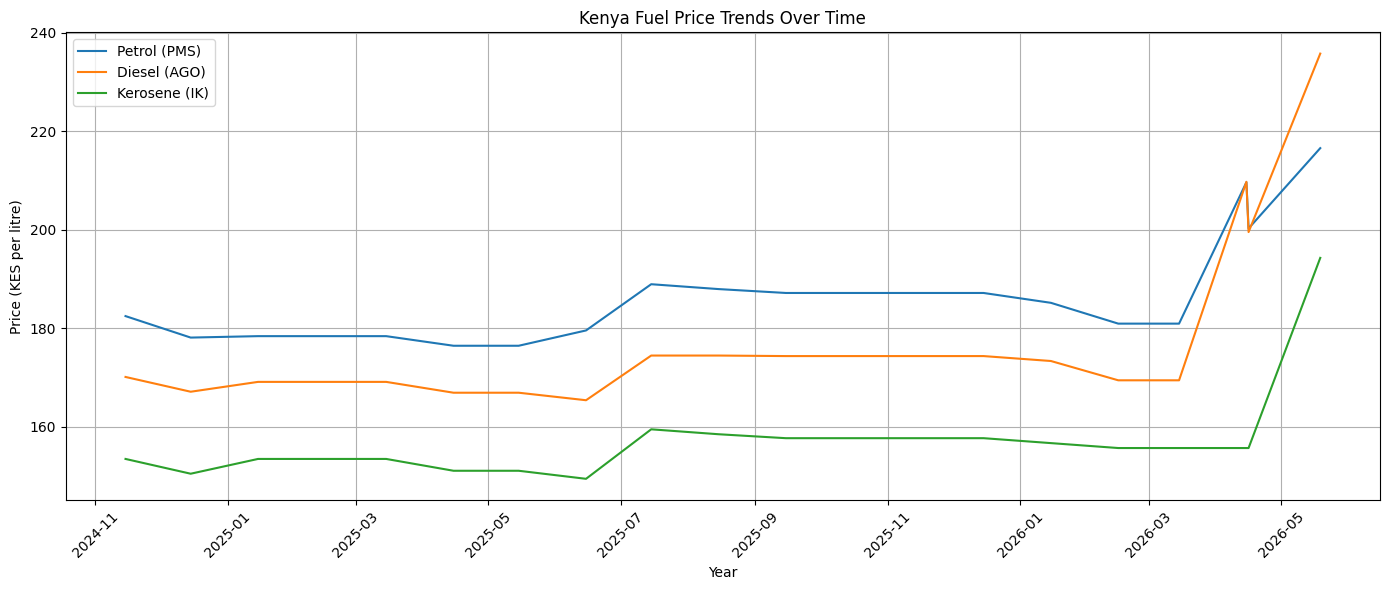

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_prices["From"],
    monthly_prices["Super (PMS)"],
    label="Petrol (PMS)"
)

plt.plot(
    monthly_prices["From"],
    monthly_prices["Diesel (AGO)"],
    label="Diesel (AGO)"
)

plt.plot(
    monthly_prices["From"],
    monthly_prices["Kerosene (IK)"],
    label="Kerosene (IK)"
)

plt.title("Kenya Fuel Price Trends Over Time")
plt.xlabel("Year")
plt.ylabel("Price (KES per litre)")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

`Interpretetion`

From the graph, fuel prices (Petrol, Diesel, and Kerosene) show:

- A **relatively stable period from late 2024 to early 2026**

- Small fluctuations with slight rises and dips

- A **sharp upward spike starting around 2026-03 to 2026-05**

- Diesel shows the **steepest increase**, followed by petrol, then kerosene

Overall, the trend shifts from **stability - sudden escalation**.

`2026-03 to 2026-05 (sharp increase period)`

It shows a **break from stability into a rapid price surge**.

What happens in this period:
- Fuel prices remain stable or unchanged around **March 2026**

- A sudden rise begins in **April 2026**

- Another sharp increase follows into **May 2026**

- Diesel rises the fastest (over 40 KSh increase in some cycles)

`(WHY this spike happened)`

**a) Global crude oil price shock**

- Middle East geopolitical tensions (especially Iran-related disruptions) affected global oil supply

- Reduced supply - higher international oil prices

- Kenya imports all fuel, so prices rise directly

**b) Weak currency pressure (Kenyan Shilling)**

- Fuel is paid in US dollars

- Any weakening of the shilling increases import costs

- This amplified the price jump even further

**c) Higher landed cost of fuel imports**

- Shipping + insurance + freight costs increased

- EPRA data shows landed costs rising sharply in early 2026 cycles

 This directly translated into higher pump prices

**d) EPRA pricing adjustments**

- EPRA adjusts fuel monthly based on:
    - landed cost

    - taxes (VAT, excise duty)

    - transport margins

-In April–May 2026, EPRA passed through higher costs to consumers

Example: petrol and diesel both jumped sharply in April 2026 pricing cycle

e) Inflation feedback loop

- Higher fuel - higher transport costs

- Transport increases - food and goods prices rise

- This increases inflation, which pressures the economy further


Between March and May 2026, Kenya’s fuel prices show a sharp upward surge after a relatively stable period. This increase is mainly driven by rising global crude oil prices due to geopolitical tensions, a weaker Kenyan shilling, higher landed import costs, and EPRA’s monthly pricing adjustments that passed increased international costs to consumers. Diesel experienced the steepest rise, indicating its sensitivity to transport and industrial demand. This period marks a structural shift in fuel pricing, contributing to higher transport costs and overall inflation in the economy.

`Reasons for Increase in Fuel Prices in Kenya (2024–2026)`

Fuel prices in Kenya have increased since 2024 mainly due to rising global crude oil prices, geopolitical conflicts affecting oil supply chains, weakening of the Kenyan shilling, high taxes and levies, increased import and transport costs, and the EPRA monthly pricing mechanism that adjusts domestic fuel prices to reflect international market conditions.

In Kenya, fuel acts as a “base economic input,” meaning that any increase in fuel prices multiplies across all sectors of the economy, leading to inflationary pressure and higher cost of living.

#### How Fuel Prices Affect Transport Costs and Cost of Living

The fuel price trend graph shows how fuel prices in Kenya have changed over time, with noticeable periods of increase and fluctuation. These changes have a direct impact on both transport costs and the overall cost of living.

#### A. Impact on Transport Costs

Fuel is the main input in Kenya’s transport system because most forms of transport rely on petrol or diesel, including matatus, buses, boda bodas, and delivery trucks.

When fuel prices increase:

- Matatu and bus operators increase fares to cover higher fuel expenses

- Boda boda transport becomes more expensive for short-distance travel

- Logistics and delivery companies raise charges for goods transportation

This means that even a small increase in fuel prices leads to an immediate rise in transport costs for ordinary citizens.

#### B. Impact on Cost of Living

Fuel does not only affect transport — it also influences the prices of almost all goods and services.

When transport becomes expensive due to fuel price increases:

- The cost of delivering food to markets increases

- Traders raise prices of basic goods such as vegetables, flour, and cooking oil

- Electricity costs may rise in areas that depend on fuel-powered generators

- Businesses increase prices of services to cover higher operating costs

As a result, households end up spending more on daily necessities, increasing the overall cost of living.

### 2. ECO LEVY ON GOODS

The **eco-levy (extended producer responsibility levy)** is a tax or fee charged on certain products that are considered to have a **negative environmental impact**, especially those that generate waste or are difficult to recycle.

If a company imports plastic packaging:

- They pay an eco-levy on each unit or weight of plastic

- That money helps fund recycling systems and waste disposal programs

Why it matters:

The eco-levy shifts responsibility from the public to **producers and importers**, making them accountable for the environmental impact of their products.

From Kenya’s Finance Bill 2024 discussions, the eco-levy is a **proposed environmental tax** on certain goods that create pollution or waste, especially:

- Plastics and packaging materials

- Electronics (phones, computers, TVs)

- Batteries, tyres, and similar waste-heavy products

- Diapers and sanitary items (in earlier proposals, later debated/exempted in some cases)

It is meant to:

- Fund waste management and recycling systems

- Reduce environmental pollution

- Push producers to take responsibility for product waste (linked to **Extended Producer Responsibility – EPR**)

Eco-levy is NOT just a general “environmental tax on harmful goods” in isolation.

It is better understood as part of Kenya’s broader **EPR + environmental taxation framework**, meaning:

- Producers/importers are made responsible for waste their products create

- It overlaps with existing EPR fees (this is why it has been controversial)

`how it overlaps with existing environmental rules, how it is applied, and who ultimately bears the cost.`

Kenya already has an EPR system, which requires producers and importers to:

- register with environmental authorities

- pay EPR compliance fees

- finance collection, recycling, and safe disposal of waste

The issue:
The eco-levy was introduced on top of this system, meaning businesses argue:

- “We are already paying EPR fees… why are we being taxed again?”

- It creates **double charging for the same environmental responsibility**



**Policy clarity and implementation confusion**

Another controversy is:

- unclear definitions of which goods are taxed and how much

- changing or debated schedules in Finance Bill discussions

- overlap between Kenya Revenue Authority (KRA) taxation and environmental agencies

This creates uncertainty for businesses planning costs.

The eco-levy is controversial because it overlaps with existing EPR environmental fees, increases production and consumer costs, raises concerns about inflation, and creates uncertainty for businesses, while critics also question whether Kenya has sufficient recycling systems to justify the tax as a true environmental solution rather than an additional revenue measure.

Government proposes levy -- Stakeholders object -- Committee revises proposal.

In [26]:

# Eco Levy data from Finance Bill 2024

eco_df = pd.DataFrame({
    "Product": [
        "Diapers",
        "Telephone Sets",
        "Batteries/Dry Cells",
        "Monitors/Projectors"
    ],
    "Eco_Levy": [
        150,
        225,
        750,
        1275
    ]
})

# Sort for better visualization
eco_df = eco_df.sort_values(
    by="Eco_Levy",
    ascending=False
)

print(eco_df)

               Product  Eco_Levy
3  Monitors/Projectors      1275
2  Batteries/Dry Cells       750
1       Telephone Sets       225
0              Diapers       150


#### Graph for Eco Levy Rates by Product

- This shows the proposed tax burden.

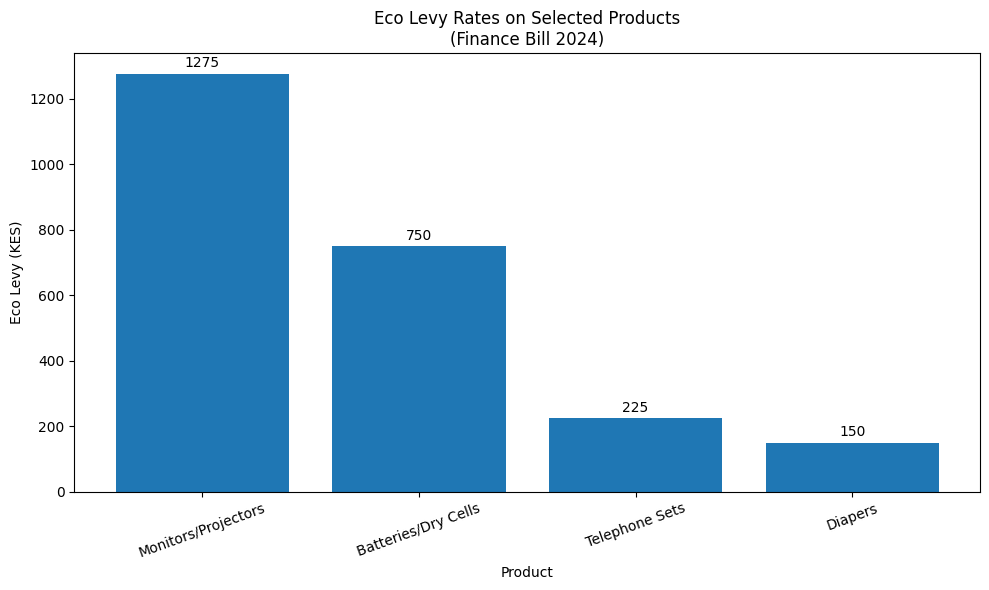

In [27]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    eco_df["Product"],
    eco_df["Eco_Levy"]
)

plt.title(
    "Eco Levy Rates on Selected Products\n(Finance Bill 2024)"
)

plt.xlabel("Product")

plt.ylabel("Eco Levy (KES)")

plt.xticks(rotation=20)

# Add value labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        f"{height}",
        ha="center"
    )

plt.tight_layout()
plt.show()

`Observation`

Monitors and projectors attracted the highest Eco Levy at KSh 1,275 per unit, followed by batteries at KSh 750 per kilogram. Telephone sets and diapers attracted lower but still significant levies.

`Interpretation`

The Eco Levy was introduced to mitigate environmental damage associated with certain manufactured and imported products. The levy seeks to internalize environmental costs by increasing the price of products that may generate waste or pollution.

`Conlusion`

The Eco Levy was introduced to help Kenya manage environmental and electronic waste by raising funds from products that may create pollution. While the idea supports environmental protection, it is still too early to measure its full impact, and concerns remain about higher consumer prices and transparency in the use of the funds.

`Critical Insight`

While the levy was presented as an environmental protection measure, some of the affected goods such as diapers are everyday household necessities. This raised concerns among stakeholders that the policy could increase consumer costs and contribute to a higher cost of living. The Committee later recommended removing the levy on diapers and reducing rates on some products in response to stakeholder concerns.

In [28]:

committee_df = pd.DataFrame({
    "Product": [
        "Diapers",
        "Motorcycle Tyres",
        "Bicycle Tyres",
        "Wheelchair Tyres",
        "Tuk Tuk Tyres",
        "Monitors",
        "Telephone Sets",
        "Batteries"
    ],
    "Status": [
        "Removed",
        "Removed",
        "Removed",
        "Removed",
        "Removed",
        "Retained/Reduced",
        "Retained/Reduced",
        "Retained/Reduced"
    ]
})

committee_df

,Product,Status
0,Diapers,Removed
1,Motorcycle Tyres,Removed
2,Bicycle Tyres,Removed
3,Wheelchair Tyres,Removed
4,Tuk Tuk Tyres,Removed
5,Monitors,Retained/Reduced
6,Telephone Sets,Retained/Reduced
7,Batteries,Retained/Reduced


In [29]:
status_counts = committee_df["Status"].value_counts()

status_counts

Status
Removed             5
Retained/Reduced    3
Name: count, dtype: int64

#### Graph for the Committee Response After Public Participation


- To show policy change.

Products moved from the proposed Eco Levy list to the exempt list after stakeholder feedback. The graph measures the extent to which public participation resulted in the retention or removal of proposed levy items.

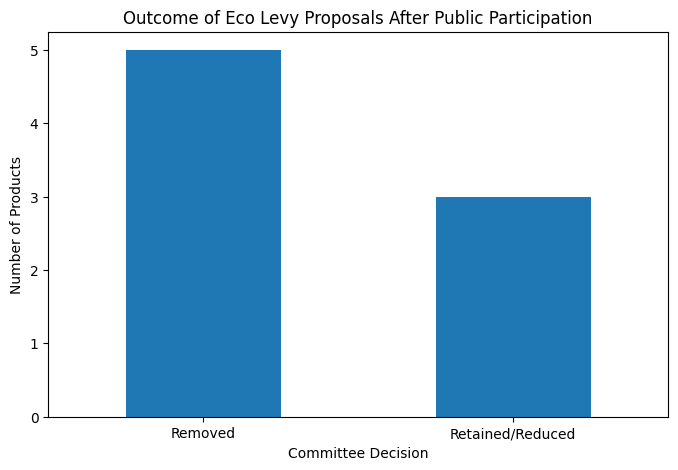

In [30]:


plt.figure(figsize=(8,5))

status_counts.plot(
    kind="bar"
)

plt.title(
    "Outcome of Eco Levy Proposals After Public Participation"
)

plt.xlabel("Committee Decision")
plt.ylabel("Number of Products")

plt.xticks(rotation=0)

plt.show()

`Observation`

The graph shows that a significant number of products initially targeted by the Eco Levy were either removed from the levy schedule or had their proposed rates revised after stakeholders submitted their views during public participation. Examples include diapers and certain tyre categories, which were considered essential products by many stakeholders.

`Interpretation`

This suggests that public participation had a measurable impact on the legislative process. Stakeholders argued that taxing essential household and transport-related products would increase the cost of living for ordinary Kenyans. As a result, the Committee reconsidered some of the original proposals before making its recommendations.

`Why it Matters`

The Eco Levy debate highlights the challenge of balancing environmental goals with affordability. While the government intended to use the levy to reduce environmental harm and encourage sustainable consumption, stakeholders were concerned that the additional costs would ultimately be passed on to consumers through higher prices. The Committee's decision to modify some of the proposals demonstrates how citizen and stakeholder feedback can influence tax policy.

`Key Insight`

The most important finding is not simply that an Eco Levy was proposed, but that public participation changed the final policy. This shows that the Finance Bill 2024 was not a one-way government decision; stakeholder concerns directly influenced which taxes were retained, revised, or removed.

### 3. DIGITAL & MOBILE MONEY TAXES

`How would the Finance Bill 2024 affect people earning income online or using digital financial services?`

The Finance Bill proposed replacing the 1.5% Digital Service Tax (DST) with a 6% Significant Economic Presence Tax (SEPT).

The Finance Bill 2024 proposed replacing the Digital Service Tax (DST) with the Significant Economic Presence Tax (SEPT). While DST taxed revenue from digital services, SEPT sought to tax non-resident businesses that earn substantial income from Kenyan users even without a physical presence in the country. The change aimed to broaden the tax base and capture more revenue from the digital economy.

**Simple Example**

Suppose a foreign streaming platform earns money from Kenyan subscribers.

**Under DST:**

- Tax is charged on the revenue generated from those services.

**Under SEPT:**

- Tax is based on the company's significant economic activity and income derived from Kenya.

In [44]:
digital_tax_comparison = pd.DataFrame({
    "Group": [
        "Freelancers",
        "Content Creators",
        "Online Sellers",
        "Digital Startups",
        "Foreign Digital Platforms"
    ],
    "Monthly Earnings (KSh)": [50000, 80000, 60000, 150000, 500000]
})

digital_tax_comparison["DST Impact (1.5%)"] = (
    digital_tax_comparison["Monthly Earnings (KSh)"] * 0.015
).round(0)

digital_tax_comparison["After DST"] = (
    digital_tax_comparison["Monthly Earnings (KSh)"] -
    digital_tax_comparison["DST Impact (1.5%)"]
).round(0)

digital_tax_comparison["SEPT Impact (6%)"] = (
    digital_tax_comparison["Monthly Earnings (KSh)"] * 0.06
).round(0)

digital_tax_comparison["After SEPT"] = (
    digital_tax_comparison["Monthly Earnings (KSh)"] -
    digital_tax_comparison["SEPT Impact (6%)"]
).round(0)

# Convert ONLY numeric columns to clean integers (removes .0)
numeric_cols = [
    "Monthly Earnings (KSh)",
    "DST Impact (1.5%)",
    "After DST",
    "SEPT Impact (6%)",
    "After SEPT"
]

digital_tax_comparison[numeric_cols] = digital_tax_comparison[numeric_cols].astype(int)

print(digital_tax_comparison)

                       Group  Monthly Earnings (KSh)  DST Impact (1.5%)  \
0                Freelancers                   50000                750   
1           Content Creators                   80000               1200   
2             Online Sellers                   60000                900   
3           Digital Startups                  150000               2250   
4  Foreign Digital Platforms                  500000               7500   

   After DST  SEPT Impact (6%)  After SEPT  
0      49250              3000       47000  
1      78800              4800       75200  
2      59100              3600       56400  
3     147750              9000      141000  
4     492500             30000      470000  


`Observation`

The proposed Significant Economic Presence Tax (SEPT) rate of 6% was four times higher than the previous Digital Service Tax rate of 1.5%.

`Interpretation`

This means digital businesses earning income from Kenya could face substantially higher tax obligations.

`Impact on Citizens`

Although the tax targets digital businesses, the additional costs could be passed on to consumers through higher prices for digital services, online platforms, and e-commerce transactions.

- `Freelancers` → moderate impact (income tax + VAT exposure)

- `Content creators` → high impact (platform monetization + withholding tax)

- `Foreign platforms` → structural tax compliance burden

- `Online sellers` → depends on turnover and platform

- `Digital Startups` → depends on scale and profitability

In [37]:

impact_scoring = pd.DataFrame({
    "Impact Score": [1, 2, 3, 4, 5],
    "Impact Level": [
        "Very Low",
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
})

print(impact_scoring)

   Impact Score Impact Level
0             1     Very Low
1             2          Low
2             3     Moderate
3             4         High
4             5    Very High


A 1–5 impact scoring scale was used to represent the relative severity of the Finance Bill's digital tax measures on different stakeholder groups, where 1 indicates very low impact and 5 indicates very high impact.

#### Graph for Affected citizens

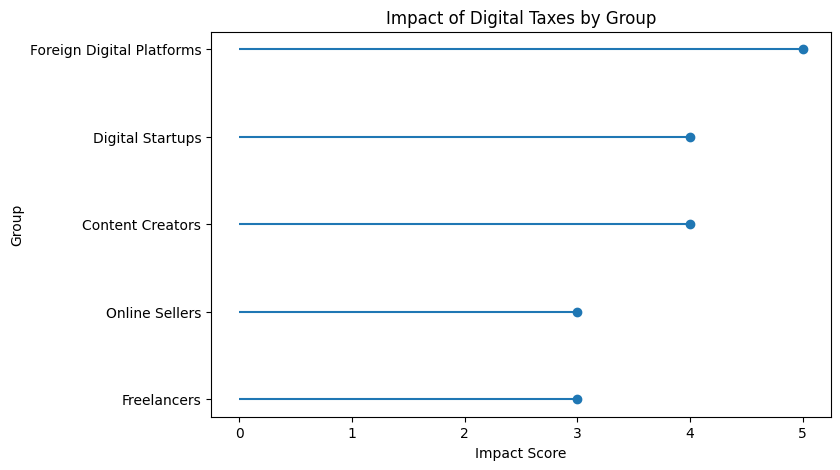

In [38]:
affected_groups = pd.DataFrame({
    "Group": [
        "Freelancers",
        "Content Creators",
        "Online Sellers",
        "Digital Startups",
        "Foreign Digital Platforms"
    ],
    "Impact": [3, 4, 3, 4, 5]       # Placeholder value(meaning 'yes' this group is affected to this extent)
})

# Sort values
affected_groups = affected_groups.sort_values("Impact")

plt.figure(figsize=(8,5))

# Draw lines
plt.hlines(
    y=affected_groups["Group"],
    xmin=0,
    xmax=affected_groups["Impact"]
)

# Draw dots
plt.plot(
    affected_groups["Impact"],
    affected_groups["Group"],
    "o"
)

plt.title("Impact of Digital Taxes by Group")
plt.xlabel("Impact Score")
plt.ylabel("Group")

plt.show()



`Observation`

- **Foreign Digital Platforms** have the highest impact score **(5)**.

- Content Creators and Digital Startups have a high impact score **(4)**.

- Freelancers and Online Sellers have a moderate impact score **(3)**.

- No group has a score below 3, suggesting that all groups are affected to some extent by digital taxation policies.

`Interpretetion`

The chart indicates that digital taxes do not affect all stakeholders equally.

- **Foreign Digital Platforms** (e.g., international streaming, advertising, or e-commerce companies) are most affected because digital taxes are largely aimed at taxing revenue generated by foreign digital services operating in Kenya.

- **Content Creators** and **Digital Startups** may experience reduced earnings or increased operating costs due to taxes on digital transactions and online income.

- **Freelancers** and **Online Sellers** are still affected, but the impact is relatively lower because many operate on a smaller scale or may not be directly targeted by some of the tax measures.

The results suggest that the burden of digital taxation is concentrated more heavily on businesses and individuals whose activities rely heavily on online platforms and digital payments.

`Impact`

The Finance Bill's digital tax measures could lead to:

**For Freelancers**
- Reduced net earnings from online work.

- Higher transaction costs when receiving payments digitally.

**For Content Creators**
- Lower take-home income from monetized content.

- Potential reduction in profitability of digital content businesses.

**For Online Sellers**
- Increased costs of operating online stores.

- Possibility of passing costs to consumers through higher prices.

**For Digital Startups**
- Higher compliance and tax obligations.

- Reduced funds available for business growth and innovation.

**For Foreign Digital Platforms**
- Increased tax liabilities on revenue generated in Kenya.

- Possible adjustment of service fees or subscription prices charged to Kenyan users.

Overall, the taxes could increase the cost of participating in the digital economy and potentially slow growth in Kenya's digital sector.

### 4. HOUSE LEVY & ADDITIONAL DEDUCTIONS

`How would the Finance Bill 2024 affect the cost of living of the ordinary Kenyans?`

- A **housing levy** is a tax on income that is specifically collected to help finance the construction of affordable homes for citizens.

`Problem`

Many employed Kenyans were concerned that the Finance Bill 2024 would reduce their disposable income through mandatory deductions.

Even though some deductions were presented as contributions toward public programs, workers wanted to understand:

- How much would be deducted from their salaries?

- How much money would remain for daily expenses?

- Which income groups would feel the biggest impact?

`Data Story`

The bill maintained the Housing Levy contribution where:

- Employee contributes **1.5% of gross salary**

- Employer contributes **1.5% of gross salary**

For employees, this means less take-home pay every month.

The effect becomes larger as income increases because the deduction rises proportionally with salary.

In [45]:
salary_levels = [30000, 50000, 100000, 200000, 300000]

housing_levy_impact = pd.DataFrame({
    "Monthly Salary (KSh)": salary_levels
})

housing_levy_impact["Housing Levy (1.5%)"] = (
    housing_levy_impact["Monthly Salary (KSh)"] * 0.015
).round(0)

housing_levy_impact["Salary After Levy"] = (
    housing_levy_impact["Monthly Salary (KSh)"] -
    housing_levy_impact["Housing Levy (1.5%)"]
).round(0)

# Convert to clean integers (removes .0)
numeric_cols = ["Monthly Salary (KSh)", "Housing Levy (1.5%)", "Salary After Levy"]

housing_levy_impact[numeric_cols] = housing_levy_impact[numeric_cols].astype(int)

print(housing_levy_impact)

   Monthly Salary (KSh)  Housing Levy (1.5%)  Salary After Levy
0                 30000                  450              29550
1                 50000                  750              49250
2                100000                 1500              98500
3                200000                 3000             197000
4                300000                 4500             295500


`Observation`

- Housing Levy deductions increase as salary increases.

- The deduction is 1.5% of gross salary for all employees.

`Interpretation`

- Although the percentage remains constant, the amount deducted grows with income.

- Every employee takes home less pay than their gross salary.

`Impact`

- Lower disposable income means less money available for food, transport, rent, healthcare, and savings.

- When combined with other taxes and deductions introduced or retained by the Finance Bill 2024, households may experience a higher cost of living.

`Results of the Finance Bill 2024`

**Positive Results**

`1. Increased Public Participation`

The Finance Bill 2024 became one of the most discussed bills in Kenya's history. Millions of Kenyans, especially young people, used social media platforms to analyze the bill, share information, and submit views.

**Why it matters:**

This demonstrated that citizens can actively influence government decisions and strengthened democratic participation.

`2. Withdrawal of the Finance Bill`

Following widespread public opposition and protests, the government withdrew the bill and declined to sign it into law.

**Why it matters:**
This showed that public participation can directly affect policy decisions and hold leaders accountable.

`3. Greater Government Accountability`

The protests forced government officials to explain proposed taxes and justify spending plans more openly.

**Why it matters:**
Citizens became more aware of how taxes are collected and how public funds are used.

`4. Increased Awareness of Public Debt`

Many Kenyans began paying attention to government borrowing, debt repayment, taxation, and national budgeting.

**Why it matters:**
An informed population can make better decisions and demand responsible fiscal management.

**Negative Results**

`1. Economic Uncertainty`

The withdrawal of the bill created a revenue gap because the government had expected to raise additional tax revenue.

**Impact:**

- Increased borrowing requirements

- Budget adjustments

- Delays in some government programs

`2. Loss of Lives and Property`

The nationwide protests led to injuries, deaths, destruction of property, and business disruptions.

**Impact:**

- Economic losses

- Social tensions

- Reduced investor confidence

`3. Higher Domestic Borrowing`

After the bill was withdrawn, the government relied more heavily on Treasury Bills and Treasury Bonds to finance the budget.

**Impact:**

- Rising domestic debt

- Higher debt servicing costs

- Less credit available for private businesses

`4. Delayed Fiscal Reforms`

Some tax measures intended to increase government revenue were postponed.

**Impact:**

- Continued budget deficits

- Increased pressure to find alternative revenue sources

`9. Recommendations and Solutions`

**Recommendation 1: Strengthen Public Participation Before Bills Are Introduced**

The government should engage citizens, businesses, youth groups, and experts much earlier when drafting finance bills.

**Why it matters:**

- Reduces public resistance.

- Improves policy quality.

- Builds trust between citizens and government.

- Prevents last-minute protests.


**Recommendation 2: Improve Transparency in Government Spending**

The government should clearly show how tax revenue is spent and publish regular progress reports on projects funded by taxpayers.

**Why it matters:**

- Increases public trust.

- Reduces perceptions of corruption.

- Encourages voluntary tax compliance.

- Helps citizens see the benefits of taxation.



**Recommendation 3: Reduce Dependence on Borrowing**

The government should focus on reducing wastage, eliminating corruption, and improving tax collection efficiency instead of relying heavily on debt.

**Why it matters:**

- Slows debt growth.

- Reduces future tax burdens.

- Frees more money for development.

- Improves long-term economic stability.


**Recommendation 4: Expand the Tax Base Instead of Increasing Tax Rates**

Rather than imposing more taxes on existing taxpayers, the government should bring more people and businesses into the formal tax system.

**Why it matters:**

- Generates sustainable revenue.

- Shares the tax burden fairly.

- Supports business growth.

- Reduces taxpayer frustration.



**Recommendation 5: Prioritize High-Impact Development Projects**

Borrowed funds should only be used for projects that generate clear economic and social benefits.

**Why it matters:**

- Ensures borrowed money creates value.

- Improves infrastructure and public services.

- Supports economic growth.

- Makes debt more sustainable.



**Recommendation 6: Use Technology to Improve Citizen Engagement**

Government agencies should use digital platforms, websites, and social media to explain proposed policies and gather feedback.

**Why it matters:**

- Reaches more citizens, especially youth.

- Encourages participation.

- Improves communication.

- Promotes transparency.



`At least 50 people died during the Finance Bill 2024 protests between June and July 2024, according to the Kenya National Commission on Human Rights (KNCHR).`

You may also see other figures because the count increased over time:

- **23 deaths** reported shortly after the June 25 protests. - The Guardian
- **39 deaths** reported by KNCHR by July 1, 2024. - Nairobi Leo
- **50 deaths** reported by KNCHR by mid-July 2024. - KCB Digital


"The Finance Bill 2024 protests resulted in at least 50 deaths, hundreds of injuries, and significant property damage. Despite these losses, the protests led to the withdrawal of the Finance Bill and demonstrated the influence of public participation on government policy."